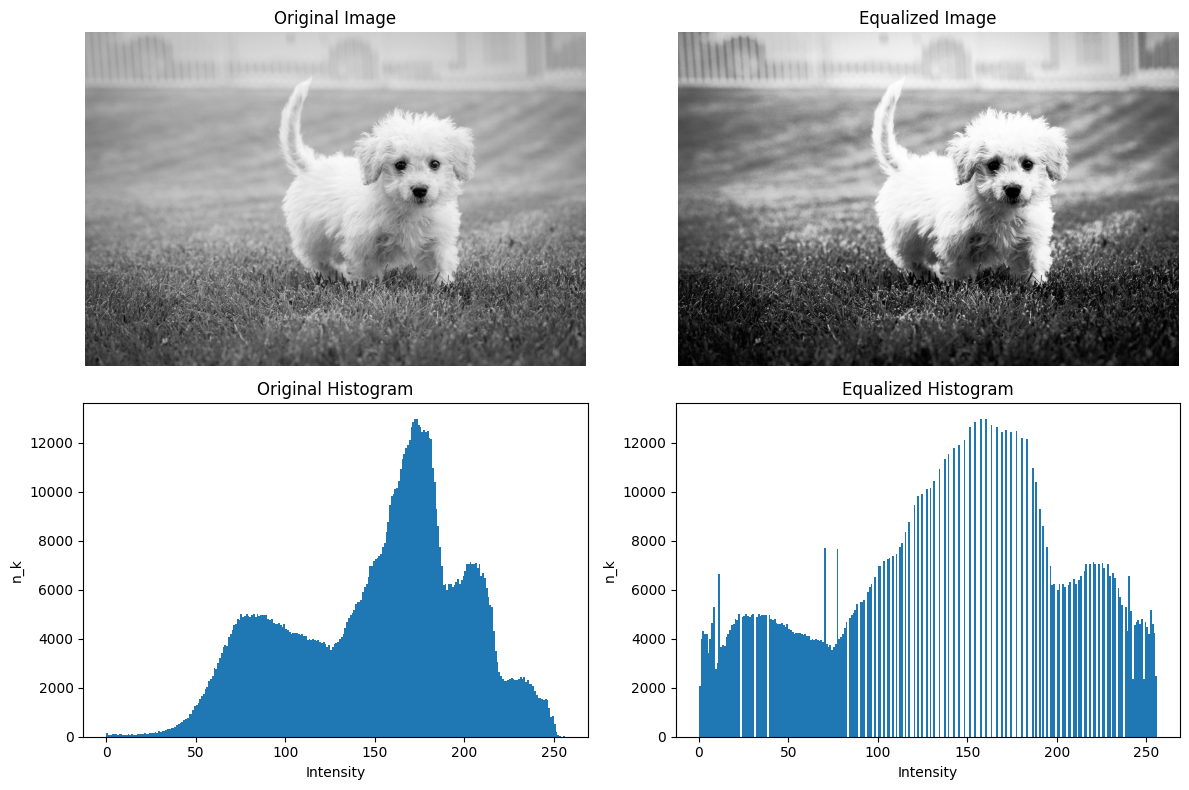

Intensity (r_k) | n_k | p_r(r_k) | CDF | s_k
-------------------------------------------------------
0  |  145  |  0.000133  |  0.000133  |  0
1  |  68  |  6.2e-05  |  0.000195  |  0
2  |  66  |  6e-05  |  0.000256  |  0
3  |  96  |  8.8e-05  |  0.000343  |  0
4  |  95  |  8.7e-05  |  0.00043  |  0
5  |  94  |  8.6e-05  |  0.000517  |  0
6  |  88  |  8.1e-05  |  0.000597  |  0
7  |  93  |  8.5e-05  |  0.000682  |  0
8  |  93  |  8.5e-05  |  0.000768  |  0
9  |  84  |  7.7e-05  |  0.000844  |  0
10  |  88  |  8.1e-05  |  0.000925  |  0
11  |  88  |  8.1e-05  |  0.001006  |  0
12  |  94  |  8.6e-05  |  0.001092  |  0
13  |  88  |  8.1e-05  |  0.001172  |  0
14  |  95  |  8.7e-05  |  0.001259  |  0
15  |  82  |  7.5e-05  |  0.001334  |  0
16  |  73  |  6.7e-05  |  0.001401  |  0
17  |  91  |  8.3e-05  |  0.001485  |  0
18  |  112  |  0.000103  |  0.001587  |  0
19  |  112  |  0.000103  |  0.00169  |  0
20  |  100  |  9.2e-05  |  0.001781  |  0
21  |  135  |  0.000124  |  0.001905  |  0
22

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread("image.jpg", cv2.IMREAD_GRAYSCALE)

# Number of pixels
M, N = img.shape
total_pixels = M * N

# Calculate histogram n_k
histogram = np.zeros(256, dtype=int)

for pixel in img.flatten():
    histogram[pixel] += 1

# Probability p_r(r_k) = n_k / (M*N)
probability = histogram / total_pixels

# Calculate cumulative distribution function (CDF)
cdf = np.cumsum(probability)

# Transformation function:
# s_k = (L-1) * CDF
L = 256
transformation = np.round((L - 1) * cdf).astype(np.uint8)

# Create equalized image
equalized_img = transformation[img]

# Display original and equalized images
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized_img, cmap="gray")
plt.title("Equalized Image")
plt.axis("off")

# Original histogram
plt.subplot(2, 2, 3)
plt.hist(img.flatten(), bins=256, range=[0, 256])
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("n_k")

# Equalized histogram
plt.subplot(2, 2, 4)
plt.hist(equalized_img.flatten(), bins=256, range=[0, 256])
plt.title("Equalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("n_k")

plt.tight_layout()
plt.show()

# Display histogram table
print("Intensity (r_k) | n_k | p_r(r_k) | CDF | s_k")
print("-" * 55)

for k in range(256):
    if histogram[k] > 0:
        print(
            k,
            " | ",
            histogram[k],
            " | ",
            round(probability[k], 6),
            " | ",
            round(cdf[k], 6),
            " | ",
            transformation[k]
        )

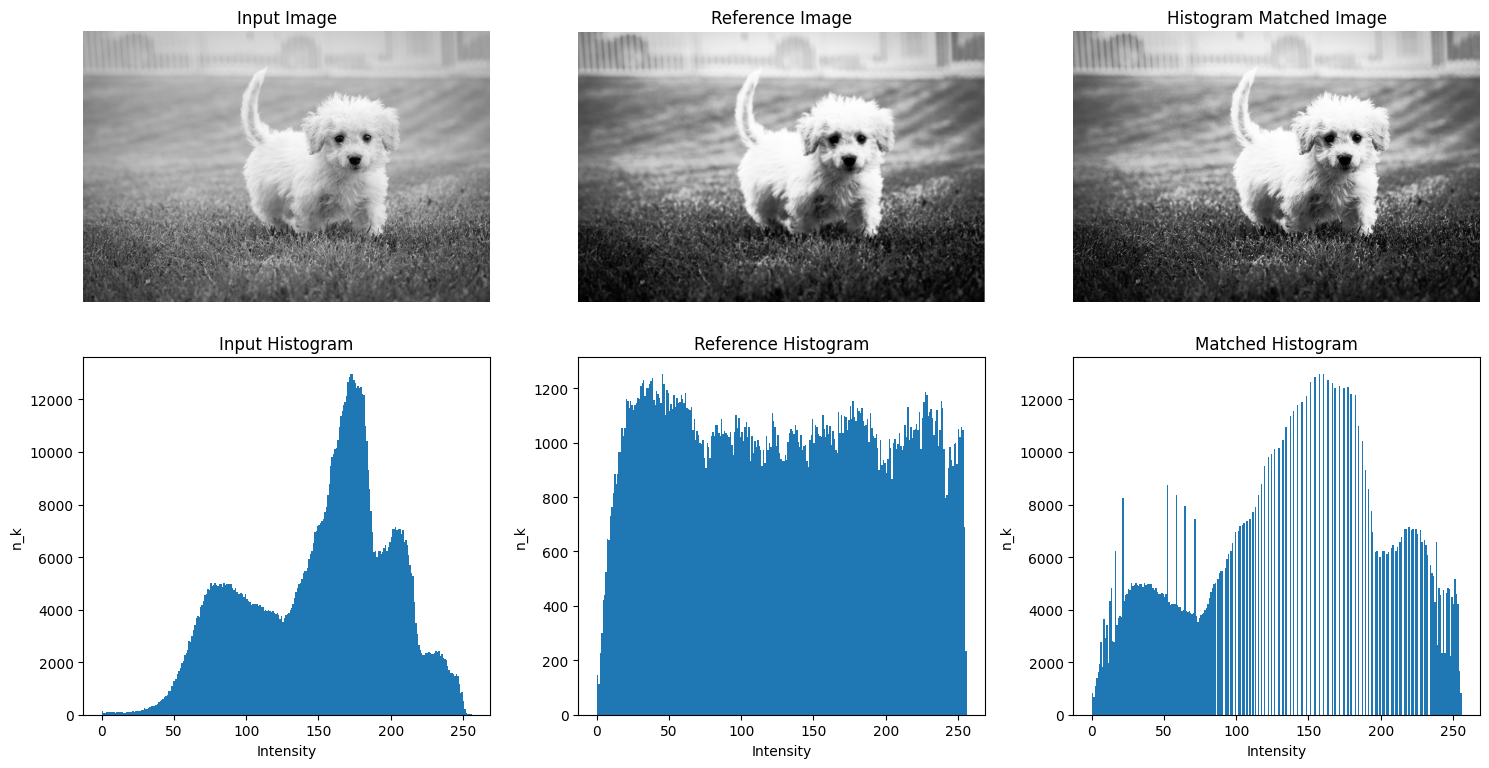

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input and reference images in grayscale
input_img = cv2.imread("image.jpg", cv2.IMREAD_GRAYSCALE)
reference_img = cv2.imread("reference.jpg", cv2.IMREAD_GRAYSCALE)

# Check if images are loaded
if input_img is None:
    print("Input image not found!")

if reference_img is None:
    print("Reference image not found!")


# ---------------------------------------------------
# STEP 1: Calculate histogram of input image
# ---------------------------------------------------

input_histogram = np.zeros(256, dtype=int)

for pixel in input_img.flatten():
    input_histogram[pixel] += 1


# ---------------------------------------------------
# STEP 2: Calculate histogram of reference image
# ---------------------------------------------------

reference_histogram = np.zeros(256, dtype=int)

for pixel in reference_img.flatten():
    reference_histogram[pixel] += 1


# ---------------------------------------------------
# STEP 3: Calculate probability of input image
# ---------------------------------------------------

input_total_pixels = input_img.shape[0] * input_img.shape[1]

input_probability = input_histogram / input_total_pixels


# ---------------------------------------------------
# STEP 4: Calculate probability of reference image
# ---------------------------------------------------

reference_total_pixels = reference_img.shape[0] * reference_img.shape[1]

reference_probability = reference_histogram / reference_total_pixels


# ---------------------------------------------------
# STEP 5: Calculate CDF
# ---------------------------------------------------

input_cdf = np.cumsum(input_probability)

reference_cdf = np.cumsum(reference_probability)


# ---------------------------------------------------
# STEP 6: Create mapping between input and reference
# ---------------------------------------------------

mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):

    # Find reference intensity having closest CDF
    difference = np.abs(reference_cdf - input_cdf[i])

    mapping[i] = np.argmin(difference)


# ---------------------------------------------------
# STEP 7: Generate histogram matched image
# ---------------------------------------------------

matched_img = mapping[input_img]


# ---------------------------------------------------
# STEP 8: Display images
# ---------------------------------------------------

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(input_img, cmap="gray")
plt.title("Input Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(reference_img, cmap="gray")
plt.title("Reference Image")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(matched_img, cmap="gray")
plt.title("Histogram Matched Image")
plt.axis("off")


# ---------------------------------------------------
# STEP 9: Display histograms
# ---------------------------------------------------

plt.subplot(2, 3, 4)
plt.hist(input_img.flatten(), bins=256, range=[0, 256])
plt.title("Input Histogram")
plt.xlabel("Intensity")
plt.ylabel("n_k")

plt.subplot(2, 3, 5)
plt.hist(reference_img.flatten(), bins=256, range=[0, 256])
plt.title("Reference Histogram")
plt.xlabel("Intensity")
plt.ylabel("n_k")

plt.subplot(2, 3, 6)
plt.hist(matched_img.flatten(), bins=256, range=[0, 256])
plt.title("Matched Histogram")
plt.xlabel("Intensity")
plt.ylabel("n_k")

plt.tight_layout()
plt.show()